# Tolke verdata med Pandas – grunnlag

Her ser me på data frå ein verstasjon (Raspberry Pi med Enviro+) som stod ute på Øvre Kråkenes frå 15. november til 4. desember 2022. Stasjonen målte omtrent kvart 33. sekund.

| Kolonne | Forklaring | Eining |
|---|---|---|
| `dato` | Tidspunkt for målinga | |
| `temperatur` | Lufttemperatur | °C |
| `lufttrykk` | Lufttrykk | hPa |
| `luftfuktighet` | Relativ luftfukt | % |
| `pm25` | Svevestøv mindre enn 2,5 µm | µg/m³ |
| `pm10` | Svevestøv mindre enn 10 µm | µg/m³ |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)  # Standard storleik på figurane

## Lese inn data

`parse_dates=["dato"]` fortel Pandas at kolonna `dato` inneheld tidspunkt. Utan dette blir datoane lesne som vanleg tekst, og då kan me ikkje rekne med dei eller plotte dei skikkeleg.

In [2]:
data = pd.read_csv("utestasjon-bones.csv", parse_dates=["dato"])
data.head()  # Viser dei fem første radene

,dato,temperatur,lufttrykk,luftfuktighet,pm25,pm10
0,2022-11-15 18:59:55.540108,25.967480,1000.728005,25.025103,1,1
1,2022-11-15 19:00:28.377546,25.853753,1000.696595,25.183850,1,3
2,2022-11-15 19:01:01.211174,26.063974,1000.721758,25.257006,2,2
3,2022-11-15 19:01:33.977001,26.058929,1000.690602,25.218070,0,2
4,2022-11-15 19:02:06.806198,25.597409,1000.692818,25.406987,0,0


In [3]:
data.dtypes  # Kva datatype har kvar kolonne? "dato" skal vere datetime64

dato             datetime64[us]
temperatur              float64
lufttrykk               float64
luftfuktighet           float64
pm25                      int64
pm10                      int64
dtype: object

In [4]:
data.describe().round(1)  # Oppsummering: tal på målingar, snitt, min, maks osv.

,dato,temperatur,lufttrykk,luftfuktighet,pm25,pm10
count,42238,42238.0,42238.0,42238.0,42238.0,42238.0
mean,2022-11-25 08:59:17.122825,6.2,1010.5,35.8,11.6,15.0
min,2022-11-15 18:59:55.540108,-2.9,991.7,17.1,0.0,0.0
25%,2022-11-20 21:33:48.531469,2.1,999.9,30.3,0.0,0.0
50%,2022-11-25 01:33:26.038008,7.1,1008.2,38.3,2.0,3.0
75%,2022-11-29 22:33:10.710376,10.3,1021.5,40.4,15.0,19.0
max,2022-12-04 09:38:23.426802,26.1,1032.7,55.1,359.0,492.0
std,NaN,4.4,12.4,6.5,19.1,24.7


In [5]:
print("Tal på målingar:", len(data))
print("Første måling:", data["dato"].min())
print("Siste måling:", data["dato"].max())
print("Tidsrom:", data["dato"].max() - data["dato"].min())

Tal på målingar: 42238
Første måling: 2022-11-15 18:59:55.540108
Siste måling: 2022-12-04 09:38:23.426802
Tidsrom: 18 days 14:38:27.886694


## Velje ut kolonnar og rader

In [6]:
data["pm10"]  # Berre kolonna pm10

0         1
1         3
2         2
3         2
4         0
         ..
42233    15
42234    18
42235    18
42236    18
42237    18
Name: pm10, Length: 42238, dtype: int64

In [7]:
data["pm10"].mean()  # Gjennomsnittleg pm10

np.float64(14.98051517590795)

In [8]:
# Alle rader der pm10 er større enn 50
data[data["pm10"] > 50]

,dato,temperatur,lufttrykk,luftfuktighet,pm25,pm10
3253,2022-11-17 17:20:09.453373,7.037107,1001.531354,28.349279,52,59
3254,2022-11-17 17:20:42.190360,6.964210,1001.519982,28.451470,36,61
3257,2022-11-17 17:22:20.819157,6.753771,1001.468977,28.640571,43,64
3263,2022-11-17 17:25:38.192578,6.500695,1001.437979,29.218749,75,85
3264,2022-11-17 17:26:10.746454,6.369113,1001.457756,29.481061,71,99
...,...,...,...,...,...,...
41113,2022-12-03 23:18:53.376384,-0.652228,1028.115449,40.635952,39,57
41114,2022-12-03 23:19:26.659077,-0.391112,1028.115518,40.683149,45,55
41116,2022-12-03 23:20:32.509623,-0.390654,1028.083509,40.254908,43,61
41119,2022-12-03 23:22:11.221659,-0.225351,1028.088699,40.238626,42,55


In [9]:
# Alle rader der pm10 er større enn 50 OG mindre enn 100.
# NB: Bruk & (og) eller | (eller), og hugs parentesar rundt kvart vilkår.
data[(data["pm10"] > 50) & (data["pm10"] < 100)]

,dato,temperatur,lufttrykk,luftfuktighet,pm25,pm10
3253,2022-11-17 17:20:09.453373,7.037107,1001.531354,28.349279,52,59
3254,2022-11-17 17:20:42.190360,6.964210,1001.519982,28.451470,36,61
3257,2022-11-17 17:22:20.819157,6.753771,1001.468977,28.640571,43,64
3263,2022-11-17 17:25:38.192578,6.500695,1001.437979,29.218749,75,85
3264,2022-11-17 17:26:10.746454,6.369113,1001.457756,29.481061,71,99
...,...,...,...,...,...,...
41113,2022-12-03 23:18:53.376384,-0.652228,1028.115449,40.635952,39,57
41114,2022-12-03 23:19:26.659077,-0.391112,1028.115518,40.683149,45,55
41116,2022-12-03 23:20:32.509623,-0.390654,1028.083509,40.254908,43,61
41119,2022-12-03 23:22:11.221659,-0.225351,1028.088699,40.238626,42,55


In [10]:
# Alle rader med temperatur under 0 grader
data[data["temperatur"] < 0]

,dato,temperatur,lufttrykk,luftfuktighet,pm25,pm10
6262,2022-11-19 06:13:12.978590,-0.038840,1017.166856,41.540374,1,3
6263,2022-11-19 06:13:46.039871,-0.050759,1017.165892,41.430508,1,3
6264,2022-11-19 06:14:19.099152,-0.044341,1017.181567,41.336504,0,0
6265,2022-11-19 06:14:52.087337,-0.030588,1017.165143,41.336641,1,1
6266,2022-11-19 06:15:25.142747,-0.025545,1017.164549,41.331465,1,1
...,...,...,...,...,...,...
42233,2022-12-04 09:36:09.541741,-1.056492,1028.193711,39.762249,15,15
42234,2022-12-04 09:36:43.453534,-1.034487,1028.200325,39.673744,13,18
42235,2022-12-04 09:37:16.519722,-1.016149,1028.213967,39.637368,15,18
42236,2022-12-04 09:37:50.433331,-1.002396,1028.217287,39.606171,15,18


## Plotte data

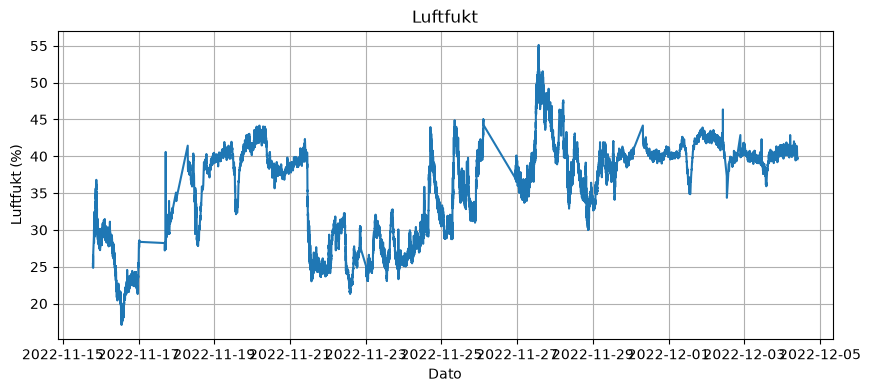

In [11]:
plt.plot(data["dato"], data["luftfuktighet"])
plt.title("Luftfukt")
plt.xlabel("Dato")
plt.ylabel("Luftfukt (%)")
plt.grid()
plt.show()

### To grafar i same figur

Med `plt.subplots(2, 1)` får me to grafar under kvarandre. `sharex=True` gir dei same x-akse, slik at det er lett å samanlikne.

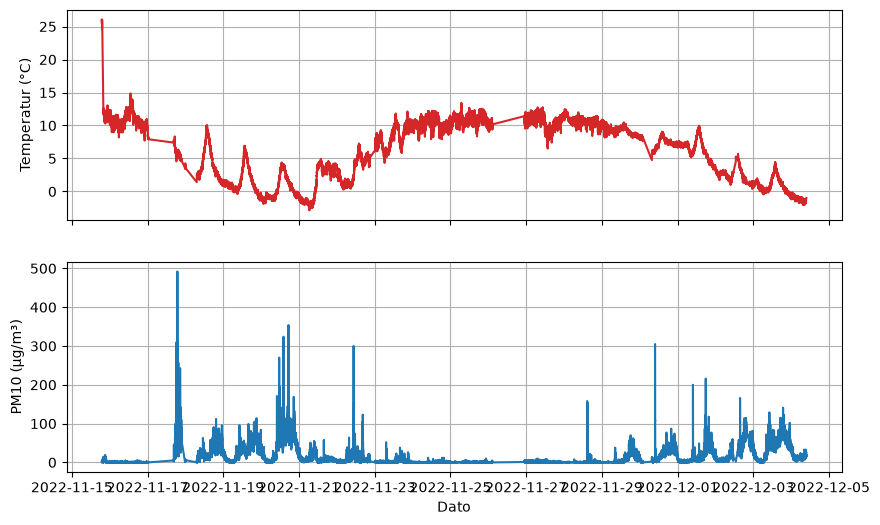

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))

ax1.plot(data["dato"], data["temperatur"], color="tab:red")
ax1.set_ylabel("Temperatur (°C)")
ax1.grid()

ax2.plot(data["dato"], data["pm10"])
ax2.set_ylabel("PM10 (µg/m³)")
ax2.set_xlabel("Dato")
ax2.grid()

plt.show()

### Plotte éin bestemt dag

Me plukkar ut radene mellom to tidspunkt. Pass på å bruke `data["dato"]` som x-akse. Brukar du berre `.plot()` på ei kolonne, blir radnummeret brukt som x-akse, og då ser du ikkje klokkeslettet.

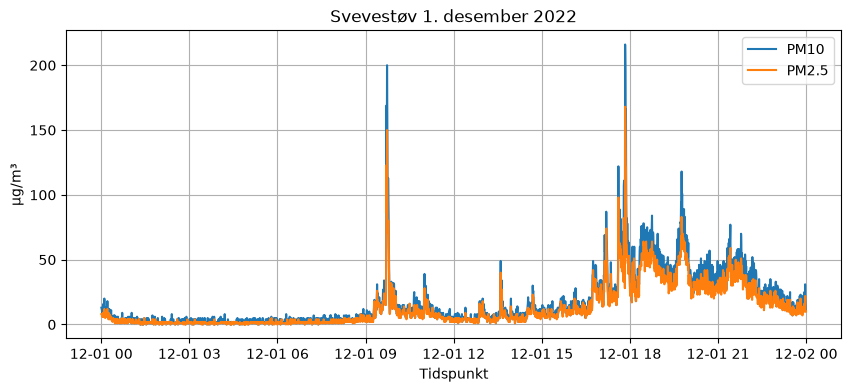

In [13]:
dag = data[(data["dato"] >= "2022-12-01") & (data["dato"] < "2022-12-02")]

plt.plot(dag["dato"], dag["pm10"], label="PM10")
plt.plot(dag["dato"], dag["pm25"], label="PM2.5")
plt.title("Svevestøv 1. desember 2022")
plt.xlabel("Tidspunkt")
plt.ylabel("µg/m³")
plt.legend()
plt.grid()
plt.show()

## Alternativ: csv-biblioteket (utan Pandas)

Det går òg an å lese fila med `csv`-biblioteket som følgjer med Python. Det krev meir kode, men viser godt kva som skjer: me går gjennom fila rad for rad, og kvar rad er ei liste med tekst.

In [14]:
import csv

with open("utestasjon-bones.csv", encoding="utf-8-sig") as fil:
    filinnhald = csv.reader(fil, delimiter=",")  # Fila er skild med komma

    overskrifter = next(filinnhald)  # Første rad er overskriftene
    print(overskrifter)

    for nummer, rad in enumerate(filinnhald):
        print(rad)
        if nummer == 4:  # Fila har over 40 000 rader, så me viser berre dei fem første
            break

['dato', 'temperatur', 'lufttrykk', 'luftfuktighet', 'pm25', 'pm10']
['2022-11-15 18:59:55.540108', '25.96747971528839', '1000.7280053646771', '25.025102687287276', '1', '1']
['2022-11-15 19:00:28.377546', '25.853752804760152', '1000.696595477291', '25.183850123620818', '1', '3']
['2022-11-15 19:01:01.211174', '26.063973628074326', '1000.7217584558009', '25.257006420247297', '2', '2']
['2022-11-15 19:01:33.977001', '26.058929292778135', '1000.6906019196086', '25.218070193098033', '0', '2']
['2022-11-15 19:02:06.806198', '25.597409050215546', '1000.6928182408237', '25.40698673404859', '0', '0']


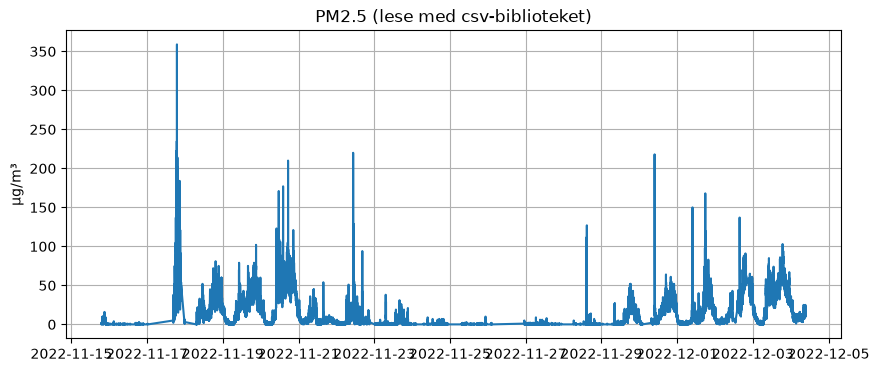

In [15]:
from datetime import datetime

# Lister for å ta vare på verdiane
tidspunkt = []
pm25 = []

with open("utestasjon-bones.csv", encoding="utf-8-sig") as fil:
    filinnhald = csv.reader(fil, delimiter=",")
    overskrifter = next(filinnhald)

    for rad in filinnhald:
        # Alt i fila er tekst, så me må gjere om til riktig datatype.
        # fromisoformat taklar tidspunkt både med og utan mikrosekund.
        tidspunkt.append(datetime.fromisoformat(rad[0]))
        pm25.append(int(rad[4]))

plt.plot(tidspunkt, pm25)
plt.title("PM2.5 (lese med csv-biblioteket)")
plt.ylabel("µg/m³")
plt.grid()
plt.show()